In [2]:
import pandas as pd
df = pd.read_excel("./../data/observaciones_10_11_2026.xlsx")
fecha = df["fecha"].dropna()
estacion_temp = df["estacion_temp"].dropna()
sensor_temp = df["sensor_temp"].dropna()

In [3]:
df.head()

,fecha,estacion_temp,estacion_hum,sensor_temp,sensor_hum,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 39,Unnamed: 40,Unnamed: 41,Unnamed: 42,Unnamed: 43,Unnamed: 44,Unnamed: 45,Unnamed: 46,Unnamed: 47,Unnamed: 48
0,2026-10-10 16:04:52,22.6,53.4,23.11,64.94,NaN,NaN,NaN,NaN,NaN,...,NaN,SUMMARY OUTPUT HUMEDAD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-10-10 16:09:53,23.0,51.5,22.86,65.60,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2026-10-10 16:14:52,23.1,52.4,22.90,65.61,NaN,NaN,NaN,NaN,NaN,...,NaN,Regression Statistics,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2026-10-10 16:19:52,23.3,52.1,22.48,66.64,NaN,NaN,NaN,NaN,NaN,...,NaN,Multiple R,0.781783,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2026-10-10 16:24:52,23.4,51.2,22.23,67.19,NaN,NaN,NaN,NaN,NaN,...,NaN,R Square,0.611185,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# ROLLING MODEL
## PERIODO OBSERVADO
### Periodo observado: del 2026-10-10 16:04:52 al 2026-10-11 16:04:53
### Datos Primeros 16 datos de la observacion
### Ventana n=4

In [7]:
# Calcular el periodo observado
fecha_inicio = fecha.min()
fecha_fin = fecha.max()

print(f"Periodo observado: del {fecha_inicio.strftime('%Y-%m-%d %H:%M:%S')} al {fecha_fin.strftime('%Y-%m-%d %H:%M:%S')}")

Periodo observado: del 2026-10-10 16:04:52 al 2026-10-11 16:04:53


In [8]:
ultimos = estacion_temp.head(16)
print(f"Valores analizados: \n{ultimos[0:8]}")
# val_esperado = ultimos[-1:]
# print(f"Valor Esperado: {val_esperado}")

# ultimos = estacion_temp.tail(30)
# print(f"Valores analizados: \n{ultimos[0:30]}")
# val_esperado = ultimos[-1:]
# print(f"Valor Esperado: {val_esperado}")

# TODOS LOS VALORES
# ultimos = estacion_temp



Valores analizados: 
0    22.6
1    23.0
2    23.1
3    23.3
4    23.4
5    23.4
6    23.8
7    24.2
Name: estacion_temp, dtype: float64


Ventana 1
Datos utilizados:
[22.6 23.  23.1 23.3]
a = -0.00648880
b = 22.76217390
Valor real siguiente = 23.4000
Valor predicho       = 23.4351
Ventana 2
Datos utilizados:
[23.  23.1 23.3 23.4]
a = -0.00644235
b = 22.89429864
Valor real siguiente = 23.4000
Valor predicho       = 23.5680
Ventana 3
Datos utilizados:
[23.1 23.3 23.4 23.4]
a = -0.00213827
b = 23.24239731
Valor real siguiente = 23.8000
Valor predicho       = 23.4668
Ventana 4
Datos utilizados:
[23.3 23.4 23.4 23.8]
a = -0.00852266
b = 23.03504189
Valor real siguiente = 24.2000
Valor predicho       = 23.9372
Ventana 5
Datos utilizados:
[23.4 23.4 23.8 24.2]
a = -0.01680633
b = 22.81122776
Valor real siguiente = 24.4000
Valor predicho       = 24.6107
Ventana 6
Datos utilizados:
[23.4 23.8 24.2 24.4]
a = -0.01241363
b = 23.39596386
Valor real siguiente = 24.0000
Valor predicho       = 24.7384
Ventana 7
Datos utilizados:
[23.8 24.2 24.4 24. ]
a = 0.00411520
b = 24.44759805
Valor real siguiente = 23.5000
Valor predicho       = 2

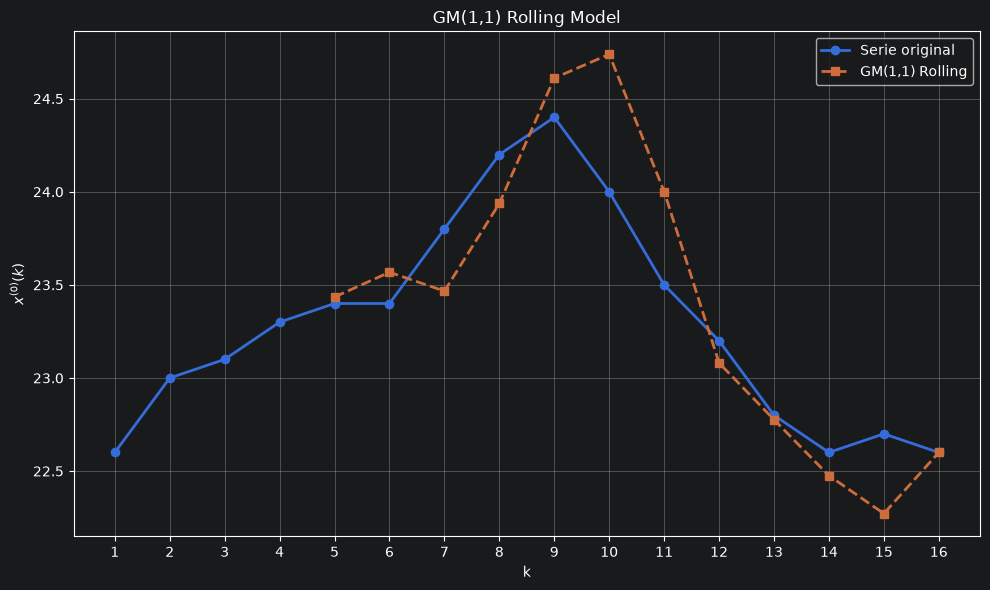

In [9]:
# ============================================================
# GM(1,1) ROLLING MODEL
# Ventana móvil de 4 observaciones
# ============================================================

import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. SERIE ORIGINAL
# ============================================================

# Sustituir por la serie que se desea analizar
X0 = ultimos.to_numpy(dtype=float)

# Tamaño de la ventana según el procedimiento descrito
ventana = 4


# ============================================================
# 2. FUNCIÓN GM(1,1)
# ============================================================

def gm11_predict_next(datos):

    """
    Ajusta un modelo GM(1,1) a los datos contenidos
    en una ventana y predice el siguiente valor.
    """

    X0_local = np.array(datos, dtype=float)

    n = len(X0_local)


    # --------------------------------------------------------
    # PASO 1: AGO
    # --------------------------------------------------------

    X1 = np.cumsum(X0_local)


    # --------------------------------------------------------
    # PASO 2: SECUENCIA DE VALORES MEDIOS Z^(1)
    # --------------------------------------------------------

    Z1 = 0.5 * (X1[1:] + X1[:-1])


    # --------------------------------------------------------
    # PASO 3: MATRIZ B Y VECTOR Y
    # --------------------------------------------------------

    B = np.column_stack((
        -Z1,
        np.ones(n - 1)
    ))

    Y = X0_local[1:].reshape(-1, 1)


    # --------------------------------------------------------
    # PASO 4: ESTIMAR a Y b
    #
    # [a b]^T = (B^T B)^(-1) B^T Y
    # --------------------------------------------------------

    parametros = np.linalg.lstsq(
        B,
        Y,
        rcond=None
    )[0]

    a = parametros[0, 0]
    b = parametros[1, 0]


    # --------------------------------------------------------
    # PASO 5: PREDECIR EL SIGUIENTE PUNTO
    #
    # Ecuación:
    #
    # x_hat^(0)(k+1)
    # =
    # (x0(1) - b/a)
    # exp(-a*k)
    # (1-exp(a))
    #
    # Para una ventana de 4 datos:
    #
    # k = 4
    #
    # para obtener el quinto valor.
    # --------------------------------------------------------

    k = n

    x_siguiente = (
        (X0_local[0] - b/a)
        * np.exp(-a*k)
        * (1 - np.exp(a))
    )

    return x_siguiente, a, b


# ============================================================
# 3. ROLLING GM(1,1)
# ============================================================

predicciones = []

parametros_a = []
parametros_b = []

indices_prediccion = []


for inicio in range(len(X0) - ventana):

    fin = inicio + ventana

    # --------------------------------------------------------
    # Extraer ventana de 4 valores REALES
    # --------------------------------------------------------

    datos_ventana = X0[inicio:fin]


    # --------------------------------------------------------
    # Construir GM(1,1) y predecir siguiente valor
    # --------------------------------------------------------

    prediccion, a, b = gm11_predict_next(
        datos_ventana
    )


    predicciones.append(prediccion)

    parametros_a.append(a)
    parametros_b.append(b)

    # Posición del dato que estamos prediciendo
    indices_prediccion.append(fin)


    # --------------------------------------------------------
    # Mostrar información de cada ventana
    # --------------------------------------------------------

    print("======================================")

    print(f"Ventana {inicio + 1}")

    print("Datos utilizados:")
    print(datos_ventana)

    print(f"a = {a:.8f}")
    print(f"b = {b:.8f}")

    print(
        f"Valor real siguiente = "
        f"{X0[fin]:.4f}"
    )

    print(
        f"Valor predicho       = "
        f"{prediccion:.4f}"
    )


# Convertir listas a numpy

predicciones = np.array(predicciones)

indices_prediccion = np.array(indices_prediccion)

parametros_a = np.array(parametros_a)

parametros_b = np.array(parametros_b)


# ============================================================
# 4. VALORES REALES CORRESPONDIENTES
# ============================================================

valores_reales = X0[ventana:]


# ============================================================
# 5. ERROR
# ============================================================

error = valores_reales - predicciones


# ============================================================
# 6. RPE
# ============================================================

RPE = (
    np.abs(error)
    / np.abs(valores_reales)
) * 100


# ============================================================
# 7. ARPE
# ============================================================

ARPE = np.mean(RPE)


print("\n")
print("======================================")
print("RESULTADOS GLOBALES")
print("======================================")

print("Valores reales:")
print(valores_reales)

print("\nPredicciones:")
print(predicciones)

print("\nErrores:")
print(error)

print("\nRPE (%):")
print(RPE)

print(f"\nARPE = {ARPE:.4f} %")


# ============================================================
# 8. GRÁFICA
# SERIE ORIGINAL Y PREDICCIÓN ROLLING
# ============================================================

k = np.arange(1, len(X0) + 1)

k_pred = np.arange(
    ventana + 1,
    len(X0) + 1
)


plt.figure(figsize=(10, 6))


plt.plot(
    k,
    X0,
    marker='o',
    linewidth=2,
    label='Serie original'
)


plt.plot(
    k_pred,
    predicciones,
    marker='s',
    linestyle='--',
    linewidth=2,
    label='GM(1,1) Rolling'
)


plt.xlabel('k')

plt.ylabel(r'$x^{(0)}(k)$')

plt.title('GM(1,1) Rolling Model')

plt.xticks(k)

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.show()

EVALUACIÓN DEL GM(1,1) ROLLING MODEL

Valores reales:
[23.4 23.4 23.8 24.2 24.4 24.  23.5 23.2 22.8 22.6 22.7 22.6]

Valores predichos:
[23.43509261 23.5679826  23.46676464 23.93717506 24.61066679 24.73840676
 24.00147354 23.08062072 22.77628282 22.47551543 22.27202622 22.59995431]

Error:
[-3.50926125e-02 -1.67982597e-01  3.33235364e-01  2.62824937e-01
 -2.10666794e-01 -7.38406757e-01 -5.01473543e-01  1.19379282e-01
  2.37171816e-02  1.24484568e-01  4.27973783e-01  4.56948547e-05]

RPE (%):
[1.49968429e-01 7.17874347e-01 1.40014859e+00 1.08605346e+00
 8.63388499e-01 3.07669482e+00 2.13392997e+00 5.14565871e-01
 1.04022727e-01 5.50816673e-01 1.88534706e+00 2.02189622e-04]

----------------------------------------
ARPE = 1.0403 %
----------------------------------------

TABLA DE RESULTADOS
 k  Valor real  Valor predicho     Error  RPE (%)
 5        23.4       23.435093 -0.035093 0.149968
 6        23.4       23.567983 -0.167983 0.717874
 7        23.8       23.466765  0.333235 1.400149

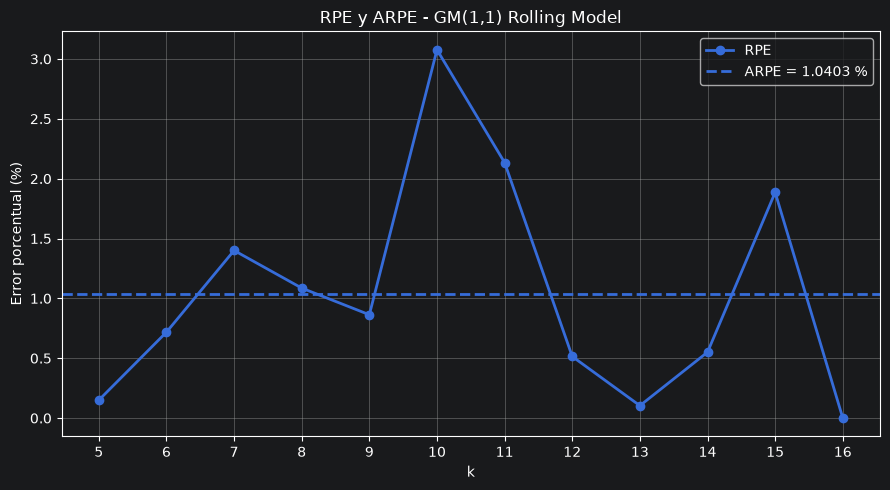

In [11]:
# ============================================================
# EVALUACIÓN DEL GM(1,1) ROLLING MODEL
# Cálculo de ERROR, RPE y ARPE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. VALORES REALES QUE FUERON PRONOSTICADOS
# ============================================================

# La ventana utilizada en el Rolling GM(1,1) es de 4 datos.
# Por lo tanto, las predicciones comienzan en el quinto dato.

valores_reales = X0[ventana:]


# ============================================================
# 2. PREDICCIONES DEL ROLLING MODEL
# ============================================================

# "predicciones" fue generado previamente por el algoritmo
# GM(1,1) Rolling.

predicciones = np.array(predicciones)


# ============================================================
# 3. ERROR
#
# epsilon(k) = x(k) - x_hat(k)
# ============================================================

error = valores_reales - predicciones


# ============================================================
# 4. RPE
#
# RPE(k) = |error(k)| / |x(k)| * 100
# ============================================================

RPE = (
    np.abs(error)
    / np.abs(valores_reales)
) * 100


# ============================================================
# 5. ARPE
#
# Promedio de todos los RPE obtenidos
# ============================================================

ARPE = np.mean(RPE)


# ============================================================
# 6. MOSTRAR RESULTADOS
# ============================================================

print("========================================")
print("EVALUACIÓN DEL GM(1,1) ROLLING MODEL")
print("========================================")

print("\nValores reales:")
print(valores_reales)

print("\nValores predichos:")
print(predicciones)

print("\nError:")
print(error)

print("\nRPE (%):")
print(RPE)

print("\n----------------------------------------")
print(f"ARPE = {ARPE:.4f} %")
print("----------------------------------------")


# ============================================================
# 7. TABLA DE RESULTADOS
# ============================================================

# Índices correspondientes a los puntos pronosticados
k_pred = np.arange(
    ventana + 1,
    len(X0) + 1
)

tabla_resultados = pd.DataFrame({

    'k': k_pred,

    'Valor real': valores_reales,

    'Valor predicho': predicciones,

    'Error': error,

    'RPE (%)': RPE

})


print("\nTABLA DE RESULTADOS")
print(tabla_resultados.to_string(index=False))


# ============================================================
# 8. GRÁFICA DEL RPE
# ============================================================

plt.figure(figsize=(9, 5))

plt.plot(
    k_pred,
    RPE,
    marker='o',
    linewidth=2,
    label='RPE'
)

# Línea correspondiente al ARPE
plt.axhline(
    y=ARPE,
    linestyle='--',
    linewidth=2,
    label=f'ARPE = {ARPE:.4f} %'
)

plt.xlabel('k')

plt.ylabel('Error porcentual (%)')

plt.title('RPE y ARPE - GM(1,1) Rolling Model')

plt.xticks(k_pred)

plt.grid(True)

plt.legend()

plt.tight_layout()

plt.show()